# Guía de laboratorio PETYLAB: Big Data con DataFrames de Spark, Delta y MongoDB
**Curso:** Base de Datos Avanzadas y Big Data (NRC 26058) · **Plataforma:** Databricks Free Edition (serverless) · **Lenguaje:** PySpark

## Logro de aprendizaje
Ingestar, limpiar, analizar y medir el procesamiento de los datos de la veterinaria PETYLAB en dos tamaños (**550** y **1000** registros), conectar con MongoDB Atlas y comprobar **si la respuesta sube o baja cuando los datos crecen**.

## Cómo trabajar
Ejecute cada celda con **Shift + Enter**, de arriba hacia abajo. Donde diga **📸 CAPTURA** tome una foto de pantalla con el código de evidencia (E-xx). Responda las preguntas de comprensión en celdas de texto nuevas. En Databricks, `spark` y `display()` ya están disponibles.

## Conceptos clave
| Concepto | Descripción |
|---|---|
| DataFrame de Spark | Colección distribuida de filas con columnas tipadas; se procesa en paralelo. |
| Medallion (Bronze / Silver / Gold) | Capas: dato crudo → dato limpio → dato analítico listo para el dashboard. |
| Transformación | Produce un nuevo DataFrame (`filter`, `select`, `join`...); es diferida. |
| Acción | Dispara la ejecución (`count`, `show`, `display`, `write`). |
| Delta | Formato de tabla con transacciones sobre Parquet; es el formato de las tablas de este laboratorio. |
| Documento embebido | Registro de MongoDB que contiene objetos y listas (la cita lleva su mascota, cliente e ítems). |

## Parte 0. Preparación (nada que subir, nada que conectar)
Este notebook es **autosuficiente**, como el del docente: **no usa SQL Server ni archivos externos**. Los datos de PETYLAB (550 clientes y mascotas, 836 citas) vienen incluidos en la Parte 2, **ya anonimizados** (sin nombres, teléfonos, direcciones ni DNI reales), y el notebook genera con las mismas reglas del script SQL las ventas, pagos, inventario y metas.
1. Importe el notebook y conéctelo a **Serverless**.
2. Ejecútelo **dos veces**: con `etiqueta_datos = 550` ("antes") y con `1000` ("después"). Con 1000 se agregan clientes **sintéticos** hasta llegar a 1000, con la misma proporción de citas. La tabla `pipeline_tiempos` junta ambas corridas.
3. Para los experimentos y el dashboard se usa un esquema/volumen de Databricks (se crean solos si el permiso lo permite; si no, créelos en Catalog: esquema `petylab`, volumen `raw`).

> El archivo tiene 4 tipos de registro (`tipo_registro`): `CITA`, `VENTA` (línea vendida), `MOVIMIENTO` (inventario) y `META` (meta mensual). Montos, inventario y metas son sintéticos de práctica; las filas agregadas para llegar a 1000 (DNI `SIM...`) y las réplicas de los experimentos también.

In [0]:
%pip install pymongo dnspython --quiet

Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
# Reinicia Python tras instalar la librería (hacerlo SOLO aquí, al inicio)
dbutils.library.restartPython()

## Parte 1. Parámetros
Complete los campos que aparecen **arriba del notebook**: `codEstudiante`, `integrante`, `esquema`, `volumen`, `etiqueta_datos` (`550` o `1000`) y `corregir_stock`. Luego ejecute las dos celdas siguientes.

**📸 CAPTURA E-17a:** el resultado de la última celda de esta parte (conjunto elegido).

In [0]:
dbutils.widgets.text("codEstudiante", "", "Código de estudiante (nombre de su BD en Mongo)")
dbutils.widgets.text("etiqueta_datos", "550", "Clientes del conjunto: 550 (antes) o 1000 (después)")
dbutils.widgets.text("integrante", "COMPLETAR", "Integrante que ejecuta")
dbutils.widgets.text("esquema", "petylab", "Esquema (schema)")
dbutils.widgets.text("volumen", "raw", "Volumen (volume)")
dbutils.widgets.dropdown("corregir_stock", "SI", ["SI", "NO"], "Corregir stock negativo (NO = ver el error original)")
dbutils.widgets.text("usuarioBd", "", "Usuario MongoDB")
dbutils.widgets.text("servidorMongo", "cluster0.nxdlttn.mongodb.net", "Servidor MongoDB Atlas")
dbutils.widgets.dropdown("bloque", "TODOS", ["TODOS", "EXP-04", "EXP-05", "EXP-06", "EXP-07", "EXP-08"], "Experimento a ejecutar")

In [0]:
from pyspark.sql import functions as F, Window
from pyspark.sql.types import *
import time, json, statistics, datetime as dt
import pandas as pd

CATALOG   = "workspace"
SCHEMA    = dbutils.widgets.get("esquema")
VOLUME    = dbutils.widgets.get("volumen")
CORREGIR  = dbutils.widgets.get("corregir_stock") == "SI"
COD       = dbutils.widgets.get("codEstudiante")
INTEGRANTE = dbutils.widgets.get("integrante")
BLOQUE    = dbutils.widgets.get("bloque")
ETIQ      = dbutils.widgets.get("etiqueta_datos")
T_PIPE    = []          # tiempos del pipeline por etapa (para comparar 550 vs 1000)
BASE      = f"/Volumes/{CATALOG}/{SCHEMA}/{VOLUME}"
N_CLI     = int(dbutils.widgets.get("etiqueta_datos"))     # 550 = base original; 1000 = ampliada
RUN_ID    = dt.datetime.now().strftime("RUN-%Y%m%d-%H%M")
REPS      = 5            # repeticiones por escenario (la 1.ª es "fría"); se reporta variabilidad

try:
    spark.sql(f"CREATE SCHEMA IF NOT EXISTS {CATALOG}.{SCHEMA}")
    spark.sql(f"CREATE VOLUME IF NOT EXISTS {CATALOG}.{SCHEMA}.{VOLUME}")
except Exception as e:
    print("Aviso (puede ser normal si ya existen o no tienen permiso):", str(e)[:150])
spark.sql(f"USE {CATALOG}.{SCHEMA}")
print("Spark", spark.version, "| ejecuta:", INTEGRANTE, "|", RUN_ID, "| bloque:", BLOQUE)
print("Conjunto de datos:", N_CLI, "clientes | corregir stock:", CORREGIR)      # CAPTURA E-17a

Spark 4.2.0 | ejecuta: COMPLETAR | RUN-20261124-0554 | bloque: TODOS
Conjunto de datos: 550 clientes | corregir stock: True


## Parte 2. Bronze: cargar los datos de PETYLAB (equivale a la Parte 5 de la guía del docente)
En vez de leer un CSV externo, los datos vienen **dentro del notebook** (celda siguiente, comprimida) y se arman en un DataFrame de Spark que se guarda tal cual como tabla Delta `bronze_todo`, con metadatos (`_ingesta_ts`, `_origen`).
* `BLOB` = citas y mascotas reales **anonimizadas** (clientes y mascotas 1 a 550, 836 citas; el DNI es un hash).
* Las ventas, pagos, inventario y metas se **calculan** con las reglas del script SQL (1 servicio por cita atendida, 2.º servicio cada 3.ª cita, productos en citas pares, promociones por categoría y fecha, reposición mensual de inventario, meta = venta × factor).
* Con `etiqueta_datos = 1000` se agregan clientes/mascotas/citas **sintéticos** (misma proporción de citas por cliente).

**📸 CAPTURA E-17b:** conteo por `tipo_registro` y el esquema (**una captura con 550 y otra con 1000**).

**Pregunta de comprensión:** ¿qué ventaja tiene trabajar con datos incluidos en el notebook frente a conectarse a la base de datos? ¿Qué limitación tiene (por ejemplo, la reconciliación con el Data Mart)?

In [0]:
# Datos base anonimizados (zlib + base64). Contenido: mascotas (id, cliente, hash de DNI, nacimiento, raza, especie, sexo, color, distrito),
# citas (id, mascota, fecha, hora, motivo, estado) y catálogos (razas, sexos, colores, ubicaciones).
BLOB = "..."

In [0]:
import zlib, base64, json, hashlib, math, datetime as dt
from decimal import Decimal, ROUND_HALF_UP

def _r(x, n=2):
    """ROUND de SQL Server (mitad hacia arriba)."""
    q = Decimal(1).scaleb(-n)
    return float(Decimal(str(x)).quantize(q, rounding=ROUND_HALF_UP))

SERVICIOS = [("Consulta general","Consulta",60.00),("Vacunacion","Prevencion",80.00),("Desparasitacion","Prevencion",45.00),
  ("Control post operatorio","Consulta",50.00),("Bano medicado","Estetica",70.00),("Analisis de laboratorio","Diagnostico",120.00),
  ("Ecografia","Diagnostico",150.00),("Profilaxis dental","Odontologia",180.00),("Cirugia menor","Cirugia",350.00)]
PRODUCTOS = [("Antiparasitario externo (pipeta)","Medicamento",45.00,28.00,10),("Antibiótico oral (amoxicilina)","Medicamento",38.00,22.00,10),
  ("Antiinflamatorio (meloxicam)","Medicamento",42.00,25.00,10),("Suplemento vitamínico","Medicamento",35.00,20.00,10),
  ("Collar antipulgas","Medicamento",55.00,33.00,8),("Alimento premium perro adulto 15 kg","Alimento",220.00,165.00,5),
  ("Alimento premium cachorro 7.5 kg","Alimento",130.00,95.00,6),("Alimento premium gato adulto 7.5 kg","Alimento",140.00,100.00,6),
  ("Alimento húmedo (lata)","Alimento",9.00,5.50,40),("Snacks dentales","Alimento",18.00,10.00,20),("Shampoo medicado","Higiene",40.00,24.00,8),
  ("Toallitas húmedas","Higiene",15.00,8.00,15),("Collar isabelino","Accesorio",30.00,17.00,6),("Correa reforzada","Accesorio",35.00,20.00,6)]
PROMOS = [("Prevencion",15,"2024-04-01","2024-06-30"),("Prevencion",20,"2025-01-01","2025-03-31"),("Consulta",10,"2025-04-01","2025-06-30"),
  ("Alimento",12,"2025-09-01","2025-10-31"),("Estetica",25,"2026-01-01","2026-03-31"),("Higiene",20,"2026-03-01","2026-05-31"),
  ("Diagnostico",15,"2026-04-01","2026-06-30")]
METODOS = ["Efectivo","Yape","Plin","Tarjeta","Transferencia"]
HORAS = ["09:00","10:00","11:30","13:00","14:30","15:30","17:00","18:00"]
MOTIVOS = ["Chequeo anual","Vacunación","Baño medicado","Control post operatorio","Revisión dermatológica","Desparasitación"]
D = lambda s: dt.date(int(s[0:4]), int(s[4:6]), int(s[6:8])) if len(s) == 8 else dt.date.fromisoformat(s)

def cargar(blob_b64):
    d = json.loads(zlib.decompress(base64.b64decode(blob_b64)).decode("utf-8"))
    ub = {u[2]: i + 1 for i, u in enumerate(d["catalogos"]["ubic"])}
    ubr = {i + 1: u for i, u in enumerate(d["catalogos"]["ubic"])}
    mascotas = {}
    for l in d["mascotas"]:
        seq, idc, h, fn, raza, esp, sexo, color, dist = l.split("|")
        mascotas[int(seq)] = dict(id_mascota=int(seq), id_cliente=int(idc), dni=h, fecha_nacimiento=D(fn), raza=raza, especie=esp, sexo=sexo,
                                  color=color, id_ubicacion=ub[dist])
    citas = []
    for l in d["citas"]:
        seq, idm, f, hh, mot, est = l.split("|")
        citas.append(dict(id_cita=int(seq), id_mascota=int(idm), fecha=D(f), hora=hh, motivo=mot, estado=est, id_empleado=1))
    return mascotas, citas, d["catalogos"], ubr

def ampliar(mascotas, citas, cat, n_clientes_obj):
    """Port de la ampliación SQL (clientes SIM): hasta n_clientes_obj clientes, manteniendo la razón citas/clientes."""
    n_cli0 = len({m["id_cliente"] for m in mascotas.values()}); n_cit0 = len(citas)
    nuevos = max(0, n_clientes_obj - n_cli0)
    if nuevos == 0: return mascotas, citas
    nuevas_citas = int(_r(nuevos * n_cit0 / n_cli0, 0))
    fmin = min(c["fecha"] for c in citas); fmax = max(c["fecha"] for c in citas); dias = (fmax - fmin).days + 1
    R, S, C, U = cat["razas"], cat["sexos"], cat["colores"], cat["ubic"]
    mascotas = dict(mascotas); base_m = max(mascotas)
    for i in range(1, nuevos + 1):
        idm = base_m + i; idc = n_cli0 + i
        mascotas[idm] = dict(id_mascota=idm, id_cliente=idc, dni=hashlib.sha256(f"SIM{i:07d}".encode()).hexdigest(),
            fecha_nacimiento=dt.date(2015, 1, 1) + dt.timedelta(days=(i * 11) % 3000), raza=R[i % len(R)][0], especie=R[i % len(R)][1],
            sexo=S[i % len(S)], color=C[i % len(C)], id_ubicacion=(i % len(U)) + 1)
    citas = list(citas); base_c = max(c["id_cita"] for c in citas); tot_m = len(mascotas)
    for j in range(1, nuevas_citas + 1):
        k = j % 100
        citas.append(dict(id_cita=base_c + j, id_mascota=(j * 7919 % tot_m) + 1, fecha=fmin + dt.timedelta(days=(j * 17 + base_c) % dias),
            hora=HORAS[j % 8], motivo=MOTIVOS[j % 6], estado="Atendida" if k < 78 else ("Cancelada" if k < 88 else "Pendiente"), id_empleado=1))
    return mascotas, citas

def ventas(citas, id_desde=0):
    """Líneas de servicio y producto (reglas del script SQL, deterministas)."""
    srv, prd = [], []
    for c in citas:
        if c["estado"] != "Atendida" or c["id_cita"] <= id_desde: continue
        i = c["id_cita"]
        s1 = SERVICIOS[i % 9]; srv.append(dict(id_cita=i, idx=i % 9 + 1, nombre=s1[0], categoria=s1[1], cantidad=1, precio=s1[2], desc=_r(s1[2] * 0.10) if i % 7 == 0 else 0.0, promo=None))
        if i % 3 == 0:
            s2 = SERVICIOS[(i + 4) % 9]; srv.append(dict(id_cita=i, idx=(i + 4) % 9 + 1, nombre=s2[0], categoria=s2[1], cantidad=1, precio=s2[2], desc=0.0, promo=None))
        if i % 2 == 0:
            p = PRODUCTOS[(i * 7) % 14]; prd.append(dict(id_cita=i, idx=(i * 7) % 14 + 1, nombre=p[0], categoria=p[1], cantidad=1 + i % 3, precio=p[2], desc=0.0, promo=None))
        if i % 5 == 0:
            p = PRODUCTOS[(i * 7 + 5) % 14]; prd.append(dict(id_cita=i, idx=(i * 7 + 5) % 14 + 1, nombre=p[0], categoria=p[1], cantidad=1, precio=p[2], desc=0.0, promo=None))
    return srv, prd

def promociones(lineas, fecha_de):
    for l in lineas:
        for pid, (cat_, pct, ini, fin) in enumerate(PROMOS, start=1):
            if l["categoria"] == cat_ and ini <= fecha_de[l["id_cita"]].isoformat() <= fin:
                l["promo"] = pid; l["desc"] = _r(l["cantidad"] * l["precio"] * pct / 100.0); break

def saldo_corregido(mov, productos):
    """Una entrada correctiva por producto en el primer día con saldo < 0 (saldo mínimo = 0)."""
    por = {}
    for m in mov: por.setdefault(m["id_producto"], []).append(m)
    nuevos = []
    for pid, ms in por.items():
        ms = sorted(ms, key=lambda m: (m["fecha"], 0 if m["tipo"] == "Entrada" else 1, m["id_mov"]))
        s = 0; mn = 0; dia = None
        for m in ms:
            s += m["cantidad"] if m["tipo"] == "Entrada" else -m["cantidad"]
            if s < mn: mn = s
            if s < 0 and dia is None: dia = m["fecha"]
        if mn < 0: nuevos.append(dict(id_producto=pid, fecha=dia, tipo="Entrada", cantidad=-mn, costo=PRODUCTOS[pid - 1][3], id_cita=None))
    return nuevos

def construir(blob_b64, n_clientes=550, corregir_stock=True):
    mascotas, citas, cat, ubr = cargar(blob_b64)
    n_base_cit = len(citas)
    m2, c2 = ampliar(mascotas, citas, cat, n_clientes)
    fecha_de = {c["id_cita"]: c["fecha"] for c in c2}
    # --- líneas de venta (base y nuevas se calculan con las mismas reglas; la promoción solo depende de categoría y fecha)
    srv, prd = ventas(c2); promociones(srv, fecha_de); promociones(prd, fecha_de)
    # --- pagos (uno por cita atendida con líneas)
    monto = {}
    for l in srv + prd: monto[l["id_cita"]] = monto.get(l["id_cita"], 0) + l["cantidad"] * l["precio"] - l["desc"]
    pago_de = {i: METODOS[i % 5] for i in monto}
    # --- inventario
    mov = []; k = 0
    def add(**kw):
        nonlocal k; k += 1; mov.append(dict(id_mov=k, **kw))
    for l in prd: add(id_producto=l["idx"], fecha=fecha_de[l["id_cita"]], tipo="Salida", cantidad=l["cantidad"], costo=PRODUCTOS[l["idx"] - 1][3], id_cita=l["id_cita"])
    for pid, p in enumerate(PRODUCTOS, start=1): add(id_producto=pid, fecha=dt.date(2022, 12, 31), tipo="Entrada", cantidad=p[4] + 3, costo=p[3], id_cita=None)
    tot = {}
    for m in mov:
        if m["tipo"] == "Salida":
            key = (m["id_producto"], dt.date(m["fecha"].year, m["fecha"].month, 1)); tot[key] = tot.get(key, 0) + m["cantidad"]
    for (pid, mes), t in sorted(tot.items(), key=lambda x: (x[0][1], x[0][0])):
        if pid % 3 != 0 or mes < dt.date(2026, 7, 1):
            add(id_producto=pid, fecha=mes, tipo="Entrada", cantidad=int(math.ceil(t * (1.5 if pid % 3 == 2 else 1.0))), costo=PRODUCTOS[pid - 1][3], id_cita=None)
    antes_neg = [pid for pid in {m["id_producto"] for m in mov} if sum((m["cantidad"] if m["tipo"] == "Entrada" else -m["cantidad"]) for m in mov if m["id_producto"] == pid) < 0]
    if corregir_stock:
        for n in saldo_corregido(mov, PRODUCTOS): add(**n)
    # --- metas por sede y mes (solo se crean para los meses con ventas)
    cita_de = {c["id_cita"]: c for c in c2}
    ventas_mes = {}
    for l in srv + prd:
        m = m2[cita_de[l["id_cita"]]["id_mascota"]]
        f = fecha_de[l["id_cita"]]; key = (m["id_ubicacion"], f.year, f.month)
        ventas_mes[key] = ventas_mes.get(key, 0) + l["cantidad"] * l["precio"] - l["desc"]
    factores = [0.85, 0.95, 1.05, 1.15, 1.25]
    metas = {k_: _r(v * factores[((k_[1] * 12 + k_[2] + k_[0]) % 5)], 0) for k_, v in ventas_mes.items()}
    return dict(mascotas=m2, citas=c2, srv=srv, prd=prd, pago_de=pago_de, monto=monto, mov=mov, metas=metas, ubr=ubr, antes_neg=antes_neg, n_base_cit=n_base_cit)


ESQUEMA = ("tipo_registro string, id_cita int, fecha date, estado string, motivo string, tipo_item string, id_item int, item string, categoria string, "
           "cantidad int, precio_unitario double, descuento double, id_promocion int, metodo_pago string, id_cliente int, dni string, id_mascota int, "
           "fecha_nacimiento date, especie string, raza string, sexo string, color string, id_empleado int, id_ubicacion int, departamento string, "
           "provincia string, distrito string, id_producto int, tipo_mov string, stock_minimo int, anio int, mes int, monto_meta double")
COLS = [c.split()[0] for c in ESQUEMA.split(", ")]

def filas(r):
    """Convierte el resultado a filas de UN archivo ancho (CITA, VENTA, MOVIMIENTO, META), el mismo formato del CSV."""
    out = []
    def fila(**kw): out.append(tuple(kw.get(c) for c in COLS))
    ubr, M = r["ubr"], r["mascotas"]
    def base(c):
        m = M[c["id_mascota"]]; u = ubr[m["id_ubicacion"]]
        return dict(id_cita=c["id_cita"], fecha=c["fecha"], estado=c["estado"], motivo=c["motivo"], id_cliente=m["id_cliente"], dni=m["dni"],
                    id_mascota=m["id_mascota"], fecha_nacimiento=m["fecha_nacimiento"], especie=m["especie"], raza=m["raza"], sexo=m["sexo"],
                    color=m["color"], id_empleado=c["id_empleado"], id_ubicacion=m["id_ubicacion"], departamento=u[0], provincia=u[1], distrito=u[2])
    cita_de = {c["id_cita"]: c for c in r["citas"]}
    for c in r["citas"]: fila(tipo_registro="CITA", **base(c))
    for tipo, lineas in (("Servicio", r["srv"]), ("Producto", r["prd"])):
        for l in lineas:
            fila(tipo_registro="VENTA", **base(cita_de[l["id_cita"]]), tipo_item=tipo, id_item=l["idx"], item=l["nombre"], categoria=l["categoria"],
                 cantidad=l["cantidad"], precio_unitario=l["precio"], descuento=l["desc"], id_promocion=l["promo"], metodo_pago=r["pago_de"].get(l["id_cita"]))
    for m in r["mov"]:
        p = PRODUCTOS[m["id_producto"] - 1]
        fila(tipo_registro="MOVIMIENTO", id_cita=m["id_cita"], fecha=m["fecha"], item=p[0], categoria=p[1], cantidad=m["cantidad"], precio_unitario=m["costo"],
             id_producto=m["id_producto"], tipo_mov=m["tipo"], stock_minimo=p[4])
    for (ub, a, me), v in r["metas"].items():
        u = ubr[ub]; fila(tipo_registro="META", id_ubicacion=ub, departamento=u[0], provincia=u[1], distrito=u[2], anio=a, mes=me, monto_meta=v)
    return out

In [0]:
t_b = time.perf_counter()
res = construir(BLOB, n_clientes=N_CLI, corregir_stock=CORREGIR)
raw = (spark.createDataFrame(filas(res), ESQUEMA)
       .withColumn("_ingesta_ts", F.current_timestamp()).withColumn("_origen", F.lit(f"generado_{N_CLI}")))
raw.write.mode("overwrite").option("overwriteSchema", "true").saveAsTable("bronze_todo")
bt = spark.table("bronze_todo"); N_BRONZE = bt.count()
T_PIPE.append(("1 Bronze (ingesta)", N_BRONZE, time.perf_counter() - t_b))
print("Filas totales en Bronze:", N_BRONZE, "| productos con stock final < 0 ANTES de corregir:", len(res["antes_neg"]))
bt.printSchema()
display(bt.groupBy("tipo_registro").count().orderBy("tipo_registro"))                      # CAPTURA E-17b
display(bt.limit(5))

Filas totales en Bronze: 3076 | productos con stock final < 0 ANTES de corregir: 1
root
 |-- tipo_registro: string (nullable = true)
 |-- id_cita: integer (nullable = true)
 |-- fecha: date (nullable = true)
 |-- estado: string (nullable = true)
 |-- motivo: string (nullable = true)
 |-- tipo_item: string (nullable = true)
 |-- id_item: integer (nullable = true)
 |-- item: string (nullable = true)
 |-- categoria: string (nullable = true)
 |-- cantidad: integer (nullable = true)
 |-- precio_unitario: double (nullable = true)
 |-- descuento: double (nullable = true)
 |-- id_promocion: integer (nullable = true)
 |-- metodo_pago: string (nullable = true)
 |-- id_cliente: integer (nullable = true)
 |-- dni: string (nullable = true)
 |-- id_mascota: integer (nullable = true)
 |-- fecha_nacimiento: date (nullable = true)
 |-- especie: string (nullable = true)
 |-- raza: string (nullable = true)
 |-- sexo: string (nullable = true)
 |-- color: string (nullable = true)
 |-- id_empleado: integer 

tipo_registro,count
CITA,836
META,310
MOVIMIENTO,590
VENTA,1340


tipo_registro,id_cita,fecha,estado,motivo,tipo_item,id_item,item,categoria,cantidad,precio_unitario,descuento,id_promocion,metodo_pago,id_cliente,dni,id_mascota,fecha_nacimiento,especie,raza,sexo,color,id_empleado,id_ubicacion,departamento,provincia,distrito,id_producto,tipo_mov,stock_minimo,anio,mes,monto_meta,_ingesta_ts,_origen
CITA,1,2023-04-26,Atendida,Limpieza dental,null,null,null,null,null,null,null,null,null,1,a57be6540326a82ee56e49e63cda7df8ff0524dd468062ec6452a487a9cd4b8f,1,2023-02-19,Gato,Única,Hembra,Blanco,1,2,LIMA,LIMA,LOS OLIVOS,null,null,null,null,null,null,2026-11-24T05:55:24.026Z,generado_550
CITA,2,2023-05-09,Atendida,Vacunación,null,null,null,null,null,null,null,null,null,2,3b9b527991d27d6b1eae22d08be5e1cf5760fbdcecf2e520902aba9d17ebc5ae,2,2021-04-22,Perro,Única,Hembra,Negro,1,2,LIMA,LIMA,LOS OLIVOS,null,null,null,null,null,null,2026-11-24T05:55:24.026Z,generado_550
CITA,3,2023-05-11,Atendida,Revisión dermatológica,null,null,null,null,null,null,null,null,null,3,b9efbd1011b39ab109e081c7634ce8706b6362ce404add83e40cbac43fa5e335,3,2021-10-21,Gato,Única,Hembra,Marrón,1,2,LIMA,LIMA,LOS OLIVOS,null,null,null,null,null,null,2026-11-24T05:55:24.026Z,generado_550
CITA,4,2024-05-16,Atendida,Desparasitación,null,null,null,null,null,null,null,null,null,3,b9efbd1011b39ab109e081c7634ce8706b6362ce404add83e40cbac43fa5e335,3,2021-10-21,Gato,Única,Hembra,Marrón,1,2,LIMA,LIMA,LOS OLIVOS,null,null,null,null,null,null,2026-11-24T05:55:24.026Z,generado_550
CITA,5,2023-05-06,Atendida,Revisión por cojera,null,null,null,null,null,null,null,null,null,4,ee58dc8363ae0f4f88f6f9408f5069bc28fb2fb84bd61ddb50227b770de3b453,4,2020-04-20,Perro,Boxer Alemán,Hembra,Gris,1,2,LIMA,LIMA,LOS OLIVOS,null,null,null,null,null,null,2026-11-24T05:55:24.026Z,generado_550


## Parte 3. Exploración (EDA)
Conteos por estado, serie mensual, resumen estadístico, nulos, duplicados, atípicos (IQR) y huérfanos.

**📸 CAPTURA E-18a:** tabla de nulos por tipo de registro y el resumen estadístico de las ventas.

**Pregunta de comprensión:** ¿por qué hay muchos nulos en un archivo "ancho" con varios tipos de registro? ¿Cuáles nulos son esperados y cuáles serían un error?

In [0]:
cit = bt.filter("tipo_registro = 'CITA'"); ven = bt.filter("tipo_registro = 'VENTA'")
display(cit.groupBy("estado").count().orderBy(F.desc("count")))
display(cit.withColumn("anio_mes", F.date_format("fecha", "yyyy-MM")).groupBy("anio_mes").agg(F.count("*").alias("citas")).orderBy("anio_mes"))
display(ven.select("cantidad", "precio_unitario", "descuento").summary("count","mean","stddev","min","25%","50%","75%","max"))   # E-18a

estado,count
Atendida,652
Pendiente,102
Cancelada,82


anio_mes,citas
2023-04,49
2023-05,58
2023-06,5
2023-07,18
2023-08,13
2023-09,17
2023-10,10
2023-11,16
2023-12,14
2024-01,15


summary,cantidad,precio_unitario,descuento
count,1340,1340,1340
mean,1.2455223880597015,101.28731343283582,1.424365671641791
stddev,0.5951152506528795,79.88581462866863,4.863585866807493
min,1,30.0,0.0
25%,1,45.0,0.0
50%,1,70.0,0.0
75%,1,150.0,0.0
max,3,350.0,35.0


In [0]:
# Nulos esperados vs inesperados: se evalúan SOLO las columnas que cada tipo de registro debe traer
oblig = {"CITA": ["id_cita","fecha","estado","id_cliente","dni","id_mascota","id_ubicacion"],
         "VENTA": ["id_cita","fecha","tipo_item","item","cantidad","precio_unitario","id_cliente","id_ubicacion"],
         "MOVIMIENTO": ["id_producto","fecha","tipo_mov","cantidad","stock_minimo"],
         "META": ["id_ubicacion","anio","mes","monto_meta"]}
filas = []
for tipo, cols in oblig.items():
    d = bt.filter(F.col("tipo_registro") == tipo); n = d.count()
    r = d.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in cols]).first().asDict()
    filas += [(tipo, c, int(v or 0), n) for c, v in r.items()]
nul = spark.createDataFrame(filas, "tipo string, columna string, nulos long, total long").withColumn("pct_nulos", F.round(100*F.col("nulos")/F.col("total"), 2))
display(nul.orderBy(F.desc("pct_nulos")))                                                   # CAPTURA E-18a
print("Citas duplicadas (id_cita repetido en CITA):", cit.groupBy("id_cita").count().filter("count > 1").count())
print("Ventas huérfanas (sin cita):", ven.select("id_cita").distinct().join(cit.select("id_cita"), "id_cita", "left_anti").count())
q1, q3 = ven.approxQuantile("precio_unitario", [0.25, 0.75], 0.001); iqr = q3 - q1
print("Precios atípicos (IQR):", ven.filter((F.col("precio_unitario") < q1-1.5*iqr) | (F.col("precio_unitario") > q3+1.5*iqr)).count())

tipo,columna,nulos,total,pct_nulos
CITA,id_cita,0,836,0.0
CITA,fecha,0,836,0.0
CITA,estado,0,836,0.0
CITA,id_cliente,0,836,0.0
CITA,dni,0,836,0.0
CITA,id_mascota,0,836,0.0
CITA,id_ubicacion,0,836,0.0
VENTA,id_cita,0,1340,0.0
VENTA,fecha,0,1340,0.0
VENTA,tipo_item,0,1340,0.0


Citas duplicadas (id_cita repetido en CITA): 0
Ventas huérfanas (sin cita): 0
Precios atípicos (IQR): 70


## Parte 4. Transformaciones básicas con datos de PETYLAB (equivale a las Partes 3, 4 y 6 de la guía del docente)
`filter`, `select`, `selectExpr`, `join`, `union`, `sample` y `randomSplit` con el DataFrame Bronze.

In [0]:
display(cit.filter("estado = 'Atendida'").select("id_cita", "fecha", "motivo"))                                   # filter + select
display(cit.selectExpr("id_cita", "upper(especie) AS especie_mayus", "year(fecha) AS anio"))                    # selectExpr
display(ven.join(cit.select("id_cita", F.col("estado").alias("estado_cita")), "id_cita", "inner").select("id_cita", "item", "estado_cita").limit(10))   # join
a = cit.filter("estado = 'Atendida'").select("id_cita"); b2 = cit.filter("estado = 'Cancelada'").select("id_cita")
print("union:", a.union(b2).count(), "| distinct:", a.union(b2).distinct().count())                              # union
print("Muestra 10 %:", cit.sample(0.10, seed=42).count(), "de", cit.count())
entren, prueba = cit.randomSplit([0.8, 0.2], seed=42)
print("Entrenamiento:", entren.count(), "| Prueba:", prueba.count(), "| suma:", entren.count() + prueba.count())

id_cita,fecha,motivo
770,2026-03-30,Control de peso
771,2023-07-01,Evaluación de esterilización
772,2025-05-09,Desparasitación
773,2025-12-15,Consulta general
775,2024-09-09,Limpieza dental
776,2026-01-05,Consulta general
777,2023-09-18,Evaluación de esterilización
778,2024-04-20,Revisión dermatológica
780,2026-05-07,Chequeo anual
784,2023-12-06,Revisión por cojera


id_cita,especie_mayus,anio
770,PERRO,2026
771,PERRO,2023
772,GATO,2025
773,GATO,2025
774,PERRO,2025
775,GATO,2024
776,GATO,2026
777,PERRO,2023
778,PERRO,2024
779,PERRO,2023


id_cita,item,estado_cita
1,Vacunacion,Atendida
2,Desparasitacion,Atendida
3,Control post operatorio,Atendida
3,Profilaxis dental,Atendida
4,Bano medicado,Atendida
5,Analisis de laboratorio,Atendida
7,Profilaxis dental,Atendida
8,Cirugia menor,Atendida
9,Consulta general,Atendida
9,Bano medicado,Atendida


union: 734 | distinct: 734
Muestra 10 %: 81 de 836
Entrenamiento: 675 | Prueba: 161 | suma: 836


**Pregunta de comprensión:** ¿cuáles de las instrucciones anteriores son *transformaciones* y cuáles son *acciones*? ¿Por qué la suma de entrenamiento y prueba puede no ser exactamente el total aunque se use semilla?

## Parte 5. Silver: limpieza, tipado y anonimización
Se separa el archivo por `tipo_registro` en tablas limpias, se estandarizan textos y fechas y se **anonimiza el DNI con `sha2`** (el DNI original se elimina). Se calcula `monto_neto` y `cantidad_neta`.

**📸 CAPTURA E-19:** tabla de filas por tabla Silver.

**Pregunta de comprensión:** ¿por qué se guarda `dni_hash` y no el DNI? ¿Qué datos personales ni siquiera se exportaron?

In [0]:
t_s = time.perf_counter()
def silver(df, nombre):
    df.write.mode("overwrite").option("overwriteSchema", "true").saveAsTable(f"silver_{nombre}")
    return spark.table(f"silver_{nombre}").count()
tx = lambda c: F.initcap(F.trim(F.col(c)))
cont = {}

comunes = lambda d: (d.withColumn("fecha_cita", F.to_date("fecha")).withColumn("estado", tx("estado"))
    .withColumn("dni_hash", F.sha2(F.col("dni").cast("string"), 256))
    .withColumn("edad_anios", F.floor(F.months_between(F.current_date(), F.to_date("fecha_nacimiento"))/12))
    .na.fill({"especie": "Sin dato", "raza": "Sin dato", "sexo": "Sin dato", "color": "Sin dato"}))

cont["cita"] = silver(comunes(bt.filter("tipo_registro = 'CITA'")).dropDuplicates(["id_cita"])
    .select("id_cita","fecha_cita","motivo","estado","id_cliente","dni_hash","id_mascota","edad_anios","especie","raza","sexo","color",
            "id_empleado","id_ubicacion","departamento","provincia","distrito"), "cita")

lin = (comunes(bt.filter("tipo_registro = 'VENTA'")).na.fill({"descuento": 0}).filter((F.col("cantidad") > 0) & (F.col("precio_unitario") >= 0))
    .withColumn("monto_bruto", F.col("cantidad")*F.col("precio_unitario"))
    .withColumn("monto_neto", F.col("cantidad")*F.col("precio_unitario") - F.col("descuento"))
    .withColumn("flag_descuento_excesivo", (F.col("descuento") > F.col("monto_bruto")).cast("int"))
    .withColumn("id_promocion", F.coalesce("id_promocion", F.lit(0)))
    .na.fill({"metodo_pago": "Sin Registro"}))
cont["linea_venta"] = silver(lin.select("id_cita","fecha_cita","estado","tipo_item","id_item","item","categoria","cantidad","precio_unitario","descuento",
    "monto_bruto","monto_neto","id_promocion","flag_descuento_excesivo","metodo_pago","id_cliente","dni_hash","id_mascota","especie","raza",
    "id_empleado","id_ubicacion","departamento","provincia","distrito"), "linea_venta")

cont["movimiento_inventario"] = silver(bt.filter("tipo_registro = 'MOVIMIENTO'")
    .withColumn("fecha_movimiento", F.to_date("fecha")).withColumn("tipo", tx("tipo_mov"))
    .withColumn("cantidad_neta", F.when(F.col("tipo") == "Entrada", F.col("cantidad")).otherwise(-F.col("cantidad")))
    .select("id_producto", F.col("item").alias("producto"), "categoria", "fecha_movimiento", "tipo", "cantidad", "cantidad_neta",
            F.col("precio_unitario").alias("costo_unitario"), "stock_minimo", "id_cita"), "movimiento_inventario")

cont["meta_venta"] = silver(bt.filter("tipo_registro = 'META'").select("id_ubicacion", "distrito", F.col("anio").cast("int").alias("anio"),
                            F.col("mes").cast("int").alias("mes"), "monto_meta"), "meta_venta")
cont["ubicacion"] = silver(bt.filter("id_ubicacion IS NOT NULL").select("id_ubicacion","departamento","provincia","distrito").dropDuplicates(["id_ubicacion"]), "ubicacion")

T_PIPE.append(("2 Silver (limpieza)", sum(cont.values()), time.perf_counter() - t_s))
display(spark.createDataFrame(list(cont.items()), "tabla_silver string, filas long").orderBy("tabla_silver"))   # CAPTURA E-19
display(spark.table("silver_linea_venta").groupBy("tipo_item").agg(F.count("*").alias("lineas"), F.round(F.sum("monto_neto"),2).alias("monto_neto"), F.sum("flag_descuento_excesivo").alias("descuentos_excesivos")))

tabla_silver,filas
cita,836
linea_venta,1340
meta_venta,310
movimiento_inventario,590
ubicacion,11


tipo_item,lineas,monto_neto,descuentos_excesivos
Servicio,876,101864.75,0
Producto,464,46756.6,0


## Parte 6. Gold, stock y reconciliación con el Data Mart
Se arma `gold_ventas` (una fila por línea vendida) y las tablas de KPI para el dashboard. Dos controles de calidad:
* **Stock negativo:** debe dar **0 productos** (un stock < 0 es un error de datos; se corrigió en SQL Server).
* **Reconciliación BI ↔ Big Data (opcional):** si alguien del equipo tiene la base, que ejecute `SELECT SUM(Monto_Total) FROM Fact_Cita;`; péguelo en `FACT_BI` y vuelva a ejecutar la celda. Con 550 la diferencia debería ser **0** (los datos replican la base); si no es 0, explíquelo como diferencia de réplica. Con 1000 los clientes agregados son sintéticos y pueden diferir. Si no tienen la base, déjelo en `None`.

**📸 CAPTURA E-21b:** "Productos con stock NEGATIVO: 0". **📸 CAPTURA E-27a/b:** reconciliación (550 y 1000).

In [0]:
s = lambda t: spark.table(f"silver_{t}")
t_g = time.perf_counter()
def gold(df, nombre): df.write.mode("overwrite").option("overwriteSchema","true").saveAsTable(nombre)

gold(s("linea_venta").withColumn("anio", F.year("fecha_cita")).withColumn("mes", F.month("fecha_cita")).withColumn("anio_mes", F.date_format("fecha_cita","yyyy-MM"))
     .select("id_cita","fecha_cita","anio","mes","anio_mes","estado","tipo_item","item","categoria","cantidad","precio_unitario","descuento",
             "monto_bruto","monto_neto","id_promocion","metodo_pago","id_cliente","dni_hash","id_mascota","especie","raza","id_empleado",
             "id_ubicacion","departamento","provincia","distrito"), "gold_ventas")
gv = spark.table("gold_ventas"); N0 = gv.count()
print("gold_ventas:", N0, "filas (registros reales de partida)")

fact_mes = gv.groupBy("anio","mes","id_ubicacion","distrito").agg(F.round(F.sum("monto_neto"),2).alias("facturacion"), F.countDistinct("id_cita").alias("citas_facturadas"))
meta = s("meta_venta").select("anio", "mes", "id_ubicacion", "monto_meta")
gold(fact_mes.join(meta, ["anio","mes","id_ubicacion"], "left")
     .withColumn("cumplimiento_pct", F.round(100*F.col("facturacion")/F.col("monto_meta"), 2))
     .withColumn("ticket_promedio", F.round(F.col("facturacion")/F.col("citas_facturadas"), 2)), "gold_kpi_mensual")
gold(s("cita").withColumn("anio_mes", F.date_format("fecha_cita","yyyy-MM")).groupBy("anio_mes")
     .agg(F.count("*").alias("citas"), F.sum((F.col("estado")=="Atendida").cast("int")).alias("atendidas"),
          F.sum((F.col("estado")=="Cancelada").cast("int")).alias("canceladas"), F.sum((F.col("estado")=="Pendiente").cast("int")).alias("pendientes"))
     .withColumn("tasa_cancelacion_pct", F.round(100*F.col("canceladas")/F.col("citas"), 2)), "gold_kpi_citas")
gold(gv.groupBy("tipo_item","item","categoria").agg(F.round(F.sum("monto_neto"),2).alias("ingreso"), F.sum("cantidad").alias("unidades")), "gold_top_items")
gold(gv.groupBy("especie").agg(F.round(F.sum("monto_neto"),2).alias("ingreso"), F.countDistinct("id_mascota").alias("mascotas")), "gold_ingreso_especie")

atend = s("cita").filter(F.col("estado")=="Atendida").groupBy("id_cliente").agg(F.count("*").alias("atenciones"), F.max("fecha_cita").alias("ultima_atencion"))
ref = s("cita").agg(F.max("fecha_cita")).first()[0]
gold(atend.withColumn("dias_sin_comprar", F.datediff(F.lit(ref), "ultima_atencion"))
     .withColumn("segmento", F.when(F.col("dias_sin_comprar")>180, "Inactivo").when(F.col("atenciones")>=5, "Frecuente").otherwise("Regular")), "gold_segmento_cliente")
gold(s("movimiento_inventario").groupBy("id_producto","producto","categoria","stock_minimo").agg(F.sum("cantidad_neta").alias("stock_actual"))
     .withColumn("bajo_minimo", (F.col("stock_actual") < F.col("stock_minimo")).cast("int")), "gold_stock")

T_PIPE.append(("3 Gold (KPI)", N0, time.perf_counter() - t_g))

neg = spark.table("gold_stock").filter("stock_actual < 0")
print("Productos con stock NEGATIVO:", neg.count(), "(esperado 0 tras la corrección en SQL Server)")
display(neg)                                                  # CAPTURA E-21b

FACT_BI = None          # <- opcional, ejemplo: 123456.78 (resultado de SELECT SUM(Monto_Total) FROM Fact_Cita;)
total = spark.table("gold_ventas").agg(F.round(F.sum("monto_neto"),2)).first()[0]
print("Facturación total Big Data:", total, "| Data Mart:", FACT_BI, "| diferencia:", None if FACT_BI is None else round(float(total)-FACT_BI, 2))
display(spark.sql("SELECT anio_mes, ROUND(SUM(monto_neto),2) facturacion FROM gold_ventas GROUP BY anio_mes ORDER BY anio_mes"))
display(spark.sql("SELECT segmento, COUNT(*) clientes FROM gold_segmento_cliente GROUP BY segmento"))     # CAPTURA E-21

gold_ventas: 1340 filas (registros reales de partida)
Productos con stock NEGATIVO: 0 (esperado 0 tras la corrección en SQL Server)


id_producto,producto,categoria,stock_minimo,stock_actual,bajo_minimo


Facturación total Big Data: 148621.35 | Data Mart: None | diferencia: None


anio_mes,facturacion
2023-04,9578.0
2023-05,11348.0
2023-06,1145.0
2023-07,3954.0
2023-08,2915.5
2023-09,3195.0
2023-10,1505.0
2023-11,2760.0
2023-12,3013.5
2024-01,3575.0


segmento,clientes
Inactivo,499


## Parte 7. Experimentos de Big Data (EXP-04 a EXP-08) — una sola tabla de resultados
| ID | Qué se mide | Variable que cambia | Responsable sugerido |
|---|---|---|---|
| **EXP-04** | Tiempo de dos consultas (agregación; join + ventana) | **Cantidad de registros: 500 → 1000** | Aguilar |
| **EXP-05** | Tamaño en disco y tiempo de lectura + agregación | Formato: CSV / Parquet / Delta | Ramos |
| **EXP-06** | Tiempo de agregación y de filtro por año | `repartition` 1/8/32/200 y `partitionBy` | Chujutalli |
| **EXP-07** | Tiempo del join y de la API | Hint broadcast/merge/shuffle_hash; DataFrame vs SQL | Huayllas |
| **EXP-08** | Tiempo de consulta en MongoDB | Documentos 500 → 1000 y **sin índice vs con índice** | Torres |

**Cómo se hace la "foto" por tamaño:** se parte de los registros reales (`N0`) y se arman tablas de exactamente 500 y 1000 filas. Si el tamaño pedido es mayor que `N0` se **replican filas con ruido determinista** (datos sintéticos, semilla fija). Cada tamaño se mide 5 veces (la 1.ª es "fría") y se reporta mediana, desviación, mínimo y máximo para ver **si la respuesta sube o baja**.
**Para ejecutar un solo experimento** cambien el desplegable *Experimento a ejecutar* (arriba) y vuelvan a correr esta sección. Con `TODOS` corre todo (≈ 10–25 min).

In [0]:
OBJETIVOS = [500, 1000]
RES = []                      # (run_id, integrante, experimento, escenario, filas, rep, segundos, nota)

spark.sql("""CREATE TABLE IF NOT EXISTS exp_resultados (run_id STRING, integrante STRING, experimento STRING, escenario STRING,
             filas BIGINT, rep INT, segundos DOUBLE, nota STRING, ts TIMESTAMP)""")

def ejecutar(df):                         # fuerza la ejecución completa sin guardar (serverless no permite cache)
    df.write.format("noop").mode("overwrite").save()

def medir(exp, escenario, fn, filas=None, nota="", reps=REPS):
    t = []
    for i in range(1, reps + 1):
        t0 = time.perf_counter(); fn(); d = time.perf_counter() - t0; t.append(d)
        RES.append((RUN_ID, INTEGRANTE, exp, escenario, int(filas) if filas else None, i, float(d), nota))
    print(f"{exp} | {escenario:<34} filas={filas!s:>8} | mediana={statistics.median(t):7.3f}s  mín={min(t):6.3f}  máx={max(t):6.3f}  "
          f"desv={statistics.pstdev(t):6.3f}  (1.ª fría={t[0]:.3f})")

def guardar():
    global RES
    if RES:
        (spark.createDataFrame(RES, "run_id string, integrante string, experimento string, escenario string, filas long, rep int, segundos double, nota string")
         .withColumn("ts", F.current_timestamp()).write.mode("append").saveAsTable("exp_resultados"))
        print("Guardadas", len(RES), "mediciones en exp_resultados"); RES = []

def tam_mb(path):
    def rec(p): return sum(rec(f.path) if f.isDir() else f.size for f in dbutils.fs.ls(p))
    return round(rec(path)/1024/1024, 2)

def toca(exp): return BLOQUE in ("TODOS", exp)

base = spark.table("gold_ventas")
def datos_n(n):
    """Devuelve exactamente n filas: submuestra determinista si n <= N0; si no, réplicas con ruido (SINTÉTICO, semilla fija)."""
    if n <= N0:
        return base.orderBy(F.xxhash64("id_cita", "item", "precio_unitario")).limit(n)
    k = -(-n // N0)
    r = (base.withColumn("rep", F.explode(F.sequence(F.lit(1), F.lit(k))))
         .withColumn("h", F.abs(F.xxhash64("id_cita", "item", "rep")))
         .withColumn("fecha_cita", F.when(F.col("rep") == 1, F.col("fecha_cita")).otherwise(F.date_add("fecha_cita", (F.col("h") % 61 - 30).cast("int"))))
         .withColumn("monto_neto", F.when(F.col("rep") == 1, F.col("monto_neto")).otherwise(F.round(F.col("monto_neto") * (F.lit(0.9) + (F.col("h") % 21)/100.0), 2)))
         .withColumn("id_cita", F.col("id_cita") * F.lit(k) + F.col("rep"))
         .withColumn("anio", F.year("fecha_cita")).withColumn("mes", F.month("fecha_cita")).withColumn("anio_mes", F.date_format("fecha_cita", "yyyy-MM"))
         .drop("h", "rep"))
    return r.orderBy(F.xxhash64("id_cita", "item")).limit(n)

dimU = s("ubicacion")
def q1(t): return spark.table(t).groupBy("anio_mes", "distrito", "tipo_item").agg(F.sum("monto_neto").alias("fact"), F.countDistinct("id_cita").alias("citas"))
def q2(t):
    a = spark.table(t).join(F.broadcast(dimU.select("id_ubicacion", F.col("provincia").alias("prov_dim"))), "id_ubicacion", "left") \
             .groupBy("anio_mes", "prov_dim", "item").agg(F.sum("monto_neto").alias("fact"))
    return a.withColumn("rk", F.row_number().over(Window.partitionBy("anio_mes", "prov_dim").orderBy(F.desc("fact")))).filter("rk <= 3")

### EXP-04 · Registros 500 → 1000  [Aguilar]

In [0]:
if toca("EXP-04"):
    for n in OBJETIVOS:
        tabla = f"exp_ventas_n{n}"
        t0 = time.perf_counter(); datos_n(n).write.mode("overwrite").saveAsTable(tabla)
        real = spark.table(tabla).count()
        print(f"[foto {n:>7,}] tabla {tabla}: {real:,} filas, creada en {time.perf_counter()-t0:.1f}s")
        medir("EXP-04", "Q1 agregación mes/distrito/tipo", lambda: ejecutar(q1(tabla)), filas=real)
        medir("EXP-04", "Q2 join + ventana top-3", lambda: ejecutar(q2(tabla)), filas=real)
    guardar()

[foto     500] tabla exp_ventas_n500: 500 filas, creada en 3.3s
EXP-04 | Q1 agregación mes/distrito/tipo    filas=     500 | mediana=  0.567s  mín= 0.494  máx= 0.869  desv= 0.136  (1.ª fría=0.869)
EXP-04 | Q2 join + ventana top-3            filas=     500 | mediana=  0.805s  mín= 0.688  máx= 0.991  desv= 0.109  (1.ª fría=0.991)
[foto   1,000] tabla exp_ventas_n1000: 1,000 filas, creada en 2.9s
EXP-04 | Q1 agregación mes/distrito/tipo    filas=    1000 | mediana=  0.491s  mín= 0.470  máx= 0.630  desv= 0.060  (1.ª fría=0.630)
EXP-04 | Q2 join + ventana top-3            filas=    1000 | mediana=  0.763s  mín= 0.734  máx= 0.774  desv= 0.015  (1.ª fría=0.763)
Guardadas 20 mediciones en exp_resultados


### EXP-05 · Formato de almacenamiento: CSV vs Parquet vs Delta  [Ramos]

In [0]:
if toca("EXP-05"):
    NF = 1000; d = datos_n(NF); rutas = {f: f"{BASE}/exp/fmt_{f}" for f in ["csv", "parquet", "delta"]}
    d.write.mode("overwrite").option("header", True).csv(rutas["csv"])
    d.write.mode("overwrite").parquet(rutas["parquet"]); d.write.mode("overwrite").format("delta").save(rutas["delta"])
    leer = {"csv": lambda: spark.read.option("header", True).option("inferSchema", True).csv(rutas["csv"]),
            "parquet": lambda: spark.read.parquet(rutas["parquet"]), "delta": lambda: spark.read.format("delta").load(rutas["delta"])}
    for f, lf in leer.items():
        mb = tam_mb(rutas[f])
        medir("EXP-05", f"{f} ({mb} MB)", lambda: ejecutar(lf().groupBy("anio_mes").agg(F.sum("monto_neto"))), filas=NF, nota=f"tamano_mb={mb}")
    guardar()

EXP-05 | csv (0.22 MB)                      filas=    1000 | mediana=  1.231s  mín= 1.185  máx= 2.396  desv= 0.459  (1.ª fría=2.396)
EXP-05 | parquet (0.06 MB)                  filas=    1000 | mediana=  0.855s  mín= 0.806  máx= 1.087  desv= 0.100  (1.ª fría=1.087)
EXP-05 | delta (0.07 MB)                    filas=    1000 | mediana=  0.585s  mín= 0.564  máx= 0.713  desv= 0.060  (1.ª fría=0.713)
Guardadas 15 mediciones en exp_resultados


### EXP-06 · Particiones (`repartition`) y particionado físico (`partitionBy`)  [Chujutalli]

In [0]:
if toca("EXP-06"):
    NP = 1000; d = datos_n(NP)
    for p in [1, 8, 32, 200]:
        medir("EXP-06", f"repartition({p})", lambda: ejecutar(d.repartition(p).groupBy("anio_mes", "distrito").agg(F.sum("monto_neto"))), filas=NP)
    d.write.mode("overwrite").format("delta").save(f"{BASE}/exp/plano")
    d.write.mode("overwrite").format("delta").partitionBy("anio").save(f"{BASE}/exp/part_anio")
    anio_obj = d.agg(F.max("anio")).first()[0]
    medir("EXP-06", "filtro por año SIN partitionBy", lambda: ejecutar(spark.read.format("delta").load(f"{BASE}/exp/plano").filter(F.col("anio") == anio_obj).agg(F.sum("monto_neto"))), filas=NP)
    medir("EXP-06", "filtro por año CON partitionBy", lambda: ejecutar(spark.read.format("delta").load(f"{BASE}/exp/part_anio").filter(F.col("anio") == anio_obj).agg(F.sum("monto_neto"))), filas=NP)
    guardar()

EXP-06 | repartition(1)                     filas=    1000 | mediana=  0.501s  mín= 0.448  máx= 0.583  desv= 0.044  (1.ª fría=0.583)
EXP-06 | repartition(8)                     filas=    1000 | mediana=  0.560s  mín= 0.541  máx= 0.621  desv= 0.027  (1.ª fría=0.573)
EXP-06 | repartition(32)                    filas=    1000 | mediana=  0.600s  mín= 0.570  máx= 0.615  desv= 0.017  (1.ª fría=0.604)
EXP-06 | repartition(200)                   filas=    1000 | mediana=  0.953s  mín= 0.882  máx= 1.095  desv= 0.075  (1.ª fría=1.095)
EXP-06 | filtro por año SIN partitionBy     filas=    1000 | mediana=  0.576s  mín= 0.564  máx= 0.744  desv= 0.068  (1.ª fría=0.744)
EXP-06 | filtro por año CON partitionBy     filas=    1000 | mediana=  0.545s  mín= 0.523  máx= 0.903  desv= 0.145  (1.ª fría=0.903)
Guardadas 30 mediciones en exp_resultados


### EXP-07 · Estrategia de join y API (DataFrame vs Spark SQL)  [Huayllas]

In [0]:
if toca("EXP-07"):
    NJ = 1000; h = datos_n(NJ); dim = dimU.select("id_ubicacion", F.col("distrito").alias("distrito_dim")); h.createOrReplaceTempView("v_hechos")
    for hint in ["broadcast", "merge", "shuffle_hash"]:
        medir("EXP-07", f"join hint={hint}", lambda: ejecutar(h.join(dim.hint(hint), "id_ubicacion").groupBy("distrito_dim").agg(F.sum("monto_neto"))), filas=NJ)
    medir("EXP-07", "API DataFrame", lambda: ejecutar(h.groupBy("anio_mes").agg(F.sum("monto_neto"), F.count("*"))), filas=NJ)
    medir("EXP-07", "API Spark SQL", lambda: ejecutar(spark.sql("SELECT anio_mes, SUM(monto_neto), COUNT(*) FROM v_hechos GROUP BY anio_mes")), filas=NJ)
    h.join(dim.hint("broadcast"), "id_ubicacion").explain("formatted")       # CAPTURA E-27: plan con BroadcastHashJoin
    guardar()

EXP-07 | join hint=broadcast                filas=    1000 | mediana=  0.562s  mín= 0.542  máx= 0.625  desv= 0.035  (1.ª fría=0.625)
EXP-07 | join hint=merge                    filas=    1000 | mediana=  0.687s  mín= 0.573  máx= 1.288  desv= 0.262  (1.ª fría=1.288)
EXP-07 | join hint=shuffle_hash             filas=    1000 | mediana=  0.605s  mín= 0.587  máx= 0.718  desv= 0.048  (1.ª fría=0.718)
EXP-07 | API DataFrame                      filas=    1000 | mediana=  0.376s  mín= 0.361  máx= 0.482  desv= 0.044  (1.ª fría=0.482)
EXP-07 | API Spark SQL                      filas=    1000 | mediana=  0.387s  mín= 0.373  máx= 0.418  desv= 0.016  (1.ª fría=0.394)
== Physical Plan ==
AdaptiveSparkPlan (19)
+- == Initial Plan ==
   PhotonResultStage (18)
   +- PhotonColumnarToRow (17)
      +- PhotonProject (16)
         +- PhotonBroadcastHashJoin Inner (15)
            :- PhotonFilter (9)
            :  +- PhotonProject (8)
            :     +- PhotonTopK (7)
            :        +- PhotonShuf

## Parte 8. MongoDB Atlas: conexión, carga, lectura a Spark y EXP-08 (equivale a las Partes 8 y 9 de la guía del docente)
Se usa **PyMongo** como en el ejemplo del docente (funciona en Free Edition hacia el clúster Atlas del curso).
1. La celda siguiente muestra la **IP pública de salida** de Databricks: si Atlas la bloquea, pidan al docente (o agreguen en *Network Access* de su propio clúster) esa IP.
2. Escriban el **usuario** en el campo *Usuario MongoDB* (arriba) y la **clave** cuando la celda la pida (no queda escrita en el notebook).
3. Si el servidor o las credenciales son distintos a los del docente, cambien el campo *Servidor MongoDB Atlas*.
Evidencias: E-28 (documento anidado), E-29 (colección en Atlas), E-30 (índices), E-31 (resultados EXP-08).

In [0]:
import requests
print("IP pública de salida de Databricks:", requests.get("http://checkip.amazonaws.com", timeout=10).text.strip())

IP pública de salida de Databricks: 3.145.247.154


In [0]:
import copy, random
from collections import Counter
from urllib.parse import quote_plus
from pymongo import MongoClient, ASCENDING

COD        = "petylab"
usuarioBd  = "alumno"
passwordBd = "110506.b.K"
servidor   = "cluster0.itrc7t7.mongodb.net"

uri = "mongodb+srv://" + quote_plus(usuarioBd) + ":" + quote_plus(passwordBd) + "@" + servidor + "/?retryWrites=true&w=majority"

client = MongoClient(uri, serverSelectionTimeoutMS=15000)
try:
    client.admin.command("ping")
    print("Conectado a MongoDB Atlas ✓")   # CAPTURA E-29a
except Exception as e:
    raise Exception("No se pudo conectar: " + str(e)[:300])

db = client[COD]
print("Base de datos de trabajo:", db.name)

Conectado a MongoDB Atlas ✓
Base de datos de trabajo: petylab


In [0]:
import json
from pyspark.sql import functions as F

gv = spark.table("gold_ventas")

# Documento embebido "cita" (mascota, cliente anonimizado, sede, items[]) construido con Spark
dbl = lambda c: F.col(c).cast("double").alias(c)
docs_df = (gv.groupBy("id_cita","fecha_cita","estado","metodo_pago","id_empleado","id_mascota","especie","raza","id_cliente","dni_hash","id_ubicacion","distrito")
    .agg(F.collect_list(F.struct("tipo_item","item","categoria",F.col("cantidad").cast("long").alias("cantidad"),dbl("precio_unitario"),dbl("descuento"),dbl("monto_neto"))).alias("items"),
         F.round(F.sum("monto_neto"),2).cast("double").alias("monto_total"))
    .select(F.col("id_cita").cast("long").alias("_id"), F.date_format("fecha_cita","yyyy-MM-dd").alias("fecha"), "estado", "metodo_pago",
            F.col("id_empleado").cast("long").alias("id_empleado"),
            F.struct(F.col("id_mascota").cast("long").alias("id"), "especie", "raza").alias("mascota"),
            F.struct(F.col("id_cliente").cast("long").alias("id"), "dni_hash").alias("cliente"),
            F.struct(F.col("id_ubicacion").cast("long").alias("id"), "distrito").alias("sede"), "items", "monto_total"))
display(docs_df.limit(3))                                                  # CAPTURA E-28
docs_py = [json.loads(json.dumps(r.asDict(recursive=True), default=str)) for r in docs_df.collect()]
print("Documentos cita:", len(docs_py))

col = db["citas_petylab"]; col.delete_many({})
for i in range(0, len(docs_py), 1000): col.insert_many(docs_py[i:i+1000])
print("Insertados en Mongo:", col.count_documents({}))                     # CAPTURA E-29b (también en Atlas/Compass)                                                  # CAPTURA E-29b (también en Atlas/Compass)

_id,fecha,estado,metodo_pago,id_empleado,mascota,cliente,sede,items,monto_total
1,2023-04-26,Atendida,Yape,1,"List(1, Gato, Única)","List(1, af1d9660e90353f0cf34d9f623515252bbd02a678ae01e10867673599b6f2bf2)","List(2, LOS OLIVOS)","List(List(Servicio, Vacunacion, Prevencion, 1, 80.0, 0.0, 80.0))",80.0
2,2023-05-09,Atendida,Plin,1,"List(2, Perro, Única)","List(2, cc923ba6cbd298c40ddd23c65171e44ecea2a7569e63ca56ae0e9df744295209)","List(2, LOS OLIVOS)","List(List(Servicio, Desparasitacion, Prevencion, 1, 45.0, 0.0, 45.0), List(Producto, Antiparasitario externo (pipeta), Medicamento, 3, 45.0, 0.0, 135.0))",180.0
3,2023-05-11,Atendida,Tarjeta,1,"List(3, Gato, Única)","List(3, cfdf83ff4f1b9d4d90270d089e53fdcbca49891481fe428080217d62a5f4e76f)","List(2, LOS OLIVOS)","List(List(Servicio, Control post operatorio, Consulta, 1, 50.0, 0.0, 50.0), List(Servicio, Profilaxis dental, Odontologia, 1, 180.0, 0.0, 180.0))",230.0


Documentos cita: 652
Insertados en Mongo: 652


In [0]:
import json
from pyspark.sql import functions as F
from pyspark.sql.types import (StructType, StructField, StringType, LongType, DoubleType, ArrayType)

# Leer la colección de MongoDB a un DataFrame de Spark (esquema explícito, como en el ejemplo del docente)
schema = StructType([
    StructField("_id", LongType()), StructField("fecha", StringType()), StructField("estado", StringType()), StructField("metodo_pago", StringType()),
    StructField("id_empleado", LongType()),
    StructField("mascota", StructType([StructField("id", LongType()), StructField("especie", StringType()), StructField("raza", StringType())])),
    StructField("cliente", StructType([StructField("id", LongType()), StructField("dni_hash", StringType())])),
    StructField("sede", StructType([StructField("id", LongType()), StructField("distrito", StringType())])),
    StructField("items", ArrayType(StructType([StructField("tipo_item", StringType()), StructField("item", StringType()), StructField("categoria", StringType()),
                                               StructField("cantidad", LongType()), StructField("precio_unitario", DoubleType()),
                                               StructField("descuento", DoubleType()), StructField("monto_neto", DoubleType())]))),
    StructField("monto_total", DoubleType())])

leidos = [json.loads(json.dumps(d, default=str)) for d in col.find()]
df_mongo = spark.createDataFrame(leidos, schema=schema)
df_mongo.printSchema()

display(df_mongo.select(df_mongo.columns[0], "fecha", "estado", "mascota.especie", "sede.distrito", "monto_total"))
display(df_mongo.groupBy("mascota.especie").agg(F.count("*").alias("citas"), F.round(F.sum("monto_total"), 2).alias("facturacion")).orderBy(F.desc("facturacion")))

# Tabla Delta para SQL/Genie (la primera columna es el identificador de la cita)
(df_mongo.select(df_mongo.columns[0], "fecha", "estado", "mascota.especie", "sede.distrito", "monto_total")
    .toDF("id_cita", "fecha", "estado", "especie", "distrito", "monto_total")
    .write.mode("overwrite").saveAsTable("tb_citas_mongo_petylab"))

print("Tabla creada:", spark.table("tb_citas_mongo_petylab").count(), "filas")

root
 |-- _id: long (nullable = true)
 |-- fecha: string (nullable = true)
 |-- estado: string (nullable = true)
 |-- metodo_pago: string (nullable = true)
 |-- id_empleado: long (nullable = true)
 |-- mascota: struct (nullable = true)
 |    |-- id: long (nullable = true)
 |    |-- especie: string (nullable = true)
 |    |-- raza: string (nullable = true)
 |-- cliente: struct (nullable = true)
 |    |-- id: long (nullable = true)
 |    |-- dni_hash: string (nullable = true)
 |-- sede: struct (nullable = true)
 |    |-- id: long (nullable = true)
 |    |-- distrito: string (nullable = true)
 |-- items: array (nullable = true)
 |    |-- element: struct (containsNull = true)
 |    |    |-- tipo_item: string (nullable = true)
 |    |    |-- item: string (nullable = true)
 |    |    |-- categoria: string (nullable = true)
 |    |    |-- cantidad: long (nullable = true)
 |    |    |-- precio_unitario: double (nullable = true)
 |    |    |-- descuento: double (nullable = true)
 |    |    |-- 

_id,fecha,estado,especie,distrito,monto_total
1,2023-04-26,Atendida,Gato,LOS OLIVOS,80.0
2,2023-05-09,Atendida,Perro,LOS OLIVOS,180.0
3,2023-05-11,Atendida,Gato,LOS OLIVOS,230.0
4,2024-05-16,Atendida,Gato,LOS OLIVOS,160.0
5,2023-05-06,Atendida,Perro,LOS OLIVOS,150.0
7,2023-05-06,Atendida,Perro,LOS OLIVOS,162.0
8,2023-04-20,Atendida,Perro,LOS OLIVOS,485.0
9,2023-04-21,Atendida,Gato,LOS OLIVOS,130.0
10,2023-11-13,Atendida,Gato,LOS OLIVOS,390.0
11,2023-04-28,Atendida,Perro,LOS OLIVOS,45.0


especie,citas,facturacion
Perro,528,119658.75
Gato,124,28962.6


Tabla creada: 652 filas


**Guardar resultados en MongoDB y como tabla (como la Parte 9 de la guía del docente).** Se envía un resumen pequeño: no use `toPandas()` con volúmenes grandes.

In [0]:
resumen_mongo = df_mongo.select(F.col("_id").alias("id_cita"), "fecha", "estado", F.col("mascota.especie").alias("especie"), F.col("sede.distrito").alias("distrito"), "monto_total")
registros = json.loads(resumen_mongo.toPandas().to_json(orient="records"))      # tipos nativos de Python
col_v = db["ventas"]; col_v.delete_many({}); col_v.insert_many(registros)
print("Insertados en la colección 'ventas':", col_v.count_documents({}))        # 📸 CAPTURA E-29c (también se ve en Atlas)
resumen_mongo.write.mode("overwrite").saveAsTable(f"tb_datosAnalisis_{COD or 'petylab'}")
display(spark.table(f"tb_datosAnalisis_{COD or 'petylab'}"))

Insertados en la colección 'ventas': 652


id_cita,fecha,estado,especie,distrito,monto_total
1,2023-04-26,Atendida,Gato,LOS OLIVOS,80.0
2,2023-05-09,Atendida,Perro,LOS OLIVOS,180.0
3,2023-05-11,Atendida,Gato,LOS OLIVOS,230.0
4,2024-05-16,Atendida,Gato,LOS OLIVOS,160.0
5,2023-05-06,Atendida,Perro,LOS OLIVOS,150.0
7,2023-05-06,Atendida,Perro,LOS OLIVOS,162.0
8,2023-04-20,Atendida,Perro,LOS OLIVOS,485.0
9,2023-04-21,Atendida,Gato,LOS OLIVOS,130.0
10,2023-11-13,Atendida,Gato,LOS OLIVOS,390.0
11,2023-04-28,Atendida,Perro,LOS OLIVOS,45.0


### EXP-08 · MongoDB: 500 y 1000 documentos con y sin índice  [Torres]

In [0]:
import time, statistics, datetime as dt, random, copy
from collections import Counter
from pymongo import ASCENDING
from pyspark.sql import functions as F

INTEGRANTE = "Torres"
RUN_ID = dt.datetime.now().strftime("RUN-%Y%m%d-%H%M")
REPS = 5
RES = []

spark.sql("""CREATE TABLE IF NOT EXISTS exp_resultados (run_id STRING, integrante STRING, experimento STRING, escenario STRING,
             filas BIGINT, rep INT, segundos DOUBLE, nota STRING, ts TIMESTAMP)""")

def medir(exp, escenario, fn, filas=None, nota="", reps=REPS):
    t = []
    for i in range(1, reps + 1):
        t0 = time.perf_counter(); fn(); d = time.perf_counter() - t0; t.append(d)
        RES.append((RUN_ID, INTEGRANTE, exp, escenario, int(filas) if filas else None, i, float(d), nota))
    print(f"{exp} | {escenario:<20} filas={filas!s:>6} | mediana={statistics.median(t):7.4f}s  mín={min(t):7.4f}  máx={max(t):7.4f}  desv={statistics.pstdev(t):7.4f}  (1.ª fría={t[0]:.4f})  {nota}")

def guardar():
    global RES
    if RES:
        (spark.createDataFrame(RES, "run_id string, integrante string, experimento string, escenario string, filas long, rep int, segundos double, nota string")
         .withColumn("ts", F.current_timestamp()).write.mode("append").saveAsTable("exp_resultados"))
        print("Guardadas", len(RES), "mediciones en exp_resultados"); RES = []

MONGO_OBJ = [500, 1000]
rnd = random.Random(42)

def make_docs(n):
    out, m = [], len(docs_py)
    for i in range(n):
        d = copy.deepcopy(docs_py[i % m])
        if i >= m:
            d["_id"] = 10_000_000 + i
            d["monto_total"] = round(d["monto_total"] * rnd.uniform(0.9, 1.1), 2)
        out.append(d)
    return out

esp = Counter(d["mascota"]["especie"] for d in docs_py).most_common(1)[0][0]
fechas = sorted(d["fecha"] for d in docs_py)
f1, f2 = fechas[len(fechas)//4], fechas[3*len(fechas)//4]
FILTRO = {"mascota.especie": esp, "estado": "Atendida", "fecha": {"$gte": f1, "$lt": f2}}
print("Consulta:", FILTRO)

for n in MONGO_OBJ:
    c = db["exp_citas_n" + str(n)]
    c.drop()
    docs_n = make_docs(n)
    for i in range(0, n, 2000):
        c.insert_many(docs_n[i:i+2000], ordered=False)
    for esc, usar_indice in [("Mongo SIN indice", False), ("Mongo CON indice", True)]:
        c.drop_indexes()
        if usar_indice:
            c.create_index([("mascota.especie", ASCENDING), ("estado", ASCENDING), ("fecha", ASCENDING)], name="ix_especie_estado_fecha")
        ex = c.find(FILTRO).explain()["executionStats"]
        plan = "IXSCAN" if usar_indice else "COLLSCAN"
        medir("EXP-08", esc, lambda: list(c.find(FILTRO)), filas=n,
              nota="plan=" + plan + "; examinados=" + str(ex["totalDocsExamined"]) + "; devueltos=" + str(ex["nReturned"]))

guardar()
print("Índices de la última colección (CAPTURA E-30):", db["exp_citas_n" + str(MONGO_OBJ[-1])].index_information())

Consulta: {'mascota.especie': 'Perro', 'estado': 'Atendida', 'fecha': {'$gte': '2023-11-28', '$lt': '2025-11-18'}}
EXP-08 | Mongo SIN indice     filas=   500 | mediana= 0.2600s  mín= 0.2598  máx= 0.5115  desv= 0.1006  (1.ª fría=0.5115)  plan=COLLSCAN; examinados=500; devueltos=198
EXP-08 | Mongo CON indice     filas=   500 | mediana= 0.2600s  mín= 0.2597  máx= 0.2613  desv= 0.0006  (1.ª fría=0.2600)  plan=IXSCAN; examinados=198; devueltos=198
EXP-08 | Mongo SIN indice     filas=  1000 | mediana= 0.2645s  mín= 0.2643  máx= 0.6436  desv= 0.1515  (1.ª fría=0.6436)  plan=COLLSCAN; examinados=1000; devueltos=389
EXP-08 | Mongo CON indice     filas=  1000 | mediana= 0.2641s  mín= 0.2636  máx= 0.2648  desv= 0.0004  (1.ª fría=0.2640)  plan=IXSCAN; examinados=389; devueltos=389
Guardadas 20 mediciones en exp_resultados
Índices de la última colección (CAPTURA E-30): {'_id_': {'v': 2, 'key': [('_id', 1)]}, 'ix_especie_estado_fecha': {'v': 2, 'key': [('mascota.especie', 1), ('estado', 1), ('fecha'

## Parte 9. Resultados consolidados y gráficos
**📸 CAPTURA E-29 a E-33:** tabla única de resultados (mediana, desviación, mín., máx., 1.ª corrida fría) y los dos gráficos (EXP-04 y EXP-08).

In [0]:
import pandas as pd
from pyspark.sql import functions as F

pdf = spark.table("exp_resultados").toPandas()
pdf["filas"] = pdf["filas"].fillna(0).astype(int)

resumen = (pdf.groupby(["experimento", "escenario", "filas"])["segundos"]
             .agg(n="count", mediana="median", media="mean", desv="std", minimo="min", maximo="max").round(4).reset_index())

fria = pdf[pdf["rep"] == 1].groupby(["experimento", "escenario", "filas"])["segundos"].mean().round(4).rename("fria_1a").reset_index()
resumen = resumen.merge(fria, on=["experimento", "escenario", "filas"], how="left")

display(spark.createDataFrame(resumen.sort_values(["experimento", "filas", "escenario"])))   # CAPTURA E-24..E-31 (tabla única)

experimento,escenario,filas,n,mediana,media,desv,minimo,maximo,fria_1a
EXP-04,Q1 agregación mes/distrito/tipo,500,5,0.5673,0.6131,0.1516,0.4939,0.8693,0.8693
EXP-04,Q2 join + ventana top-3,500,5,0.8052,0.811,0.1213,0.6876,0.9905,0.9905
EXP-04,Q1 agregación mes/distrito/tipo,1000,5,0.4908,0.5119,0.0667,0.47,0.6301,0.6301
EXP-04,Q2 join + ventana top-3,1000,5,0.7632,0.7569,0.0173,0.7337,0.774,0.7632
EXP-05,csv (0.22 MB),1000,5,1.2305,1.5293,0.5136,1.1848,2.3961,2.3961
EXP-05,delta (0.07 MB),1000,5,0.585,0.6206,0.0672,0.5638,0.7126,0.7126
EXP-05,parquet (0.06 MB),1000,5,0.8553,0.8978,0.1116,0.8064,1.0868,1.0868
EXP-06,filtro por año CON partitionBy,1000,5,0.545,0.6165,0.162,0.5233,0.9031,0.9031
EXP-06,filtro por año SIN partitionBy,1000,5,0.5756,0.6098,0.076,0.5642,0.7438,0.7438
EXP-06,repartition(1),1000,5,0.5011,0.5064,0.0492,0.4475,0.5834,0.5834


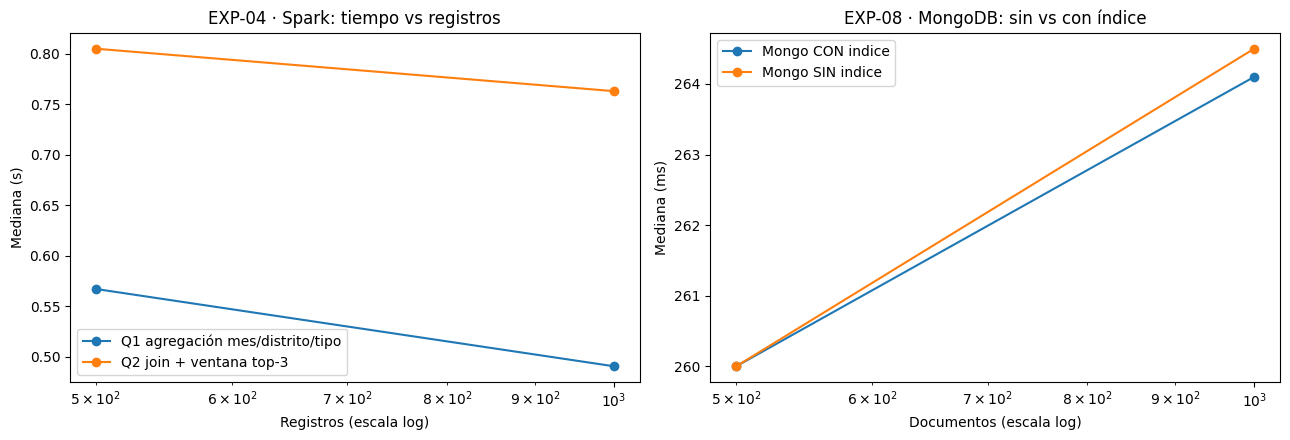

In [0]:
# Gráficos: tiempo (mediana) vs cantidad de registros. EXP-04 y EXP-08
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for esc, g in resumen[resumen["experimento"] == "EXP-04"].groupby("escenario"):
    g = g.sort_values("filas"); ax[0].plot(g["filas"], g["mediana"], marker="o", label=esc)
ax[0].set_xscale("log"); ax[0].set_xlabel("Registros (escala log)"); ax[0].set_ylabel("Mediana (s)"); ax[0].set_title("EXP-04 · Spark: tiempo vs registros"); ax[0].legend()
for esc, g in resumen[resumen["experimento"] == "EXP-08"].groupby("escenario"):
    g = g.sort_values("filas"); ax[1].plot(g["filas"], g["mediana"] * 1000, marker="o", label=esc)
ax[1].set_xscale("log"); ax[1].set_xlabel("Documentos (escala log)"); ax[1].set_ylabel("Mediana (ms)"); ax[1].set_title("EXP-08 · MongoDB: sin vs con índice"); ax[1].legend()
plt.tight_layout(); plt.show()                                                                                 # CAPTURA E-24 / E-31

In [0]:
# Lectura automática: ¿la respuesta sube o baja al crecer los registros?
for esc, g in resumen[resumen["experimento"] == "EXP-04"].groupby("escenario"):
    g = g.sort_values("filas"); a, z = g.iloc[0], g.iloc[-1]
    print(f"{esc}: de {int(a.filas):,} a {int(z.filas):,} registros (×{z.filas/a.filas:,.0f}) la mediana pasó de {a.mediana:.3f}s a {z.mediana:.3f}s (×{z.mediana/a.mediana:.2f}).")

Q1 agregación mes/distrito/tipo: de 500 a 1,000 registros (×2) la mediana pasó de 0.567s a 0.491s (×0.87).
Q2 join + ventana top-3: de 500 a 1,000 registros (×2) la mediana pasó de 0.805s a 0.763s (×0.95).


## Parte 10. Comparación del pipeline: 550 vs 1000
Esta celda guarda los tiempos de Bronze, Silver y Gold de la corrida actual con su etiqueta. Después de ejecutar el notebook con `etiqueta_datos = 550` y con `1000`, la tabla muestra ambos lado a lado.

**📸 CAPTURA E-28:** tabla `pipeline_tiempos` con 550 y 1000.

**Pregunta de comprensión:** ¿el tiempo subió, bajó o quedó igual al pasar de 550 a 1000? Con tan pocos registros el tiempo lo domina el arranque de Spark, no el volumen; compárelo con EXP-04 (500 y 1000 registros).

In [0]:
import time, datetime as dt
from pyspark.sql import functions as F

try:
    T_PIPE
except NameError:
    T_PIPE = []

ETIQ   = dbutils.widgets.get("etiqueta_datos")
RUN_ID = dt.datetime.now().strftime("RUN-%Y%m%d-%H%M")

# Si las celdas Bronze/Silver/Gold no registraron tiempos, se mide aquí la lectura completa de cada capa
if not T_PIPE:
    for etapa, tabla in [("1 Bronze (ingesta)", "bronze_todo"), ("2 Silver (limpieza)", "silver_cita"), ("3 Gold (KPI)", "gold_ventas")]:
        t0 = time.perf_counter()
        n = spark.table(tabla).count()
        T_PIPE.append((etapa, n, time.perf_counter() - t0))

spark.sql("CREATE TABLE IF NOT EXISTS pipeline_tiempos (etiqueta STRING, run_id STRING, etapa STRING, filas BIGINT, segundos DOUBLE, ts TIMESTAMP)")
(spark.createDataFrame([(ETIQ, RUN_ID, e, int(f), float(s_)) for e, f, s_ in T_PIPE], "etiqueta string, run_id string, etapa string, filas long, segundos double")
   .withColumn("ts", F.current_timestamp()).write.mode("append").saveAsTable("pipeline_tiempos"))

display(spark.sql("SELECT etiqueta, etapa, filas, ROUND(segundos, 2) AS segundos, run_id FROM pipeline_tiempos ORDER BY etapa, etiqueta"))   # CAPTURA E-46: 550 vs 1000
display(spark.sql("SELECT etiqueta, ROUND(SUM(segundos), 2) AS segundos_totales FROM pipeline_tiempos GROUP BY etiqueta ORDER BY etiqueta"))

etiqueta,etapa,filas,segundos,run_id
550,1 Bronze (ingesta),3076,0.53,RUN-20261124-0632
550,2 Silver (limpieza),836,0.36,RUN-20261124-0632
550,3 Gold (KPI),1340,0.41,RUN-20261124-0632


etiqueta,segundos_totales
550,1.3


## Parte 11. Dashboard y Genie (con la IA de Databricks) — evidencias E-35a y E-35b
**Dashboard:** menú izquierdo **Dashboards → Create dashboard → Data → Add data source** y agreguen: `gold_kpi_mensual`, `gold_top_items`, `gold_ingreso_especie`, `gold_segmento_cliente`, `gold_stock`, `gold_kpi_citas`, `exp_resultados`.
En **Canvas** pueden crear cada visual a mano o **pedírselo al asistente de IA del dashboard (Genie Code / "Ask AI")**. Prompts para pegar:
* *Crea un contador con la facturación total usando SUM(facturacion) de gold_kpi_mensual.*
* *Crea un gráfico de líneas de la facturación mensual (anio, mes) desde gold_kpi_mensual.*
* *Crea un gráfico de barras de los 10 ítems con mayor ingreso desde gold_top_items.*
* *Crea un gráfico de barras del ingreso por especie desde gold_ingreso_especie.*
* *Crea un gráfico circular de clientes por segmento desde gold_segmento_cliente.*
* *Crea una tabla con los productos bajo stock mínimo (bajo_minimo = 1) desde gold_stock.*
* *Crea un gráfico de líneas con la mediana de segundos por filas para el experimento EXP-04 desde exp_resultados.*
Revisen siempre que el asistente use las columnas correctas, agreguen filtros (año, distrito) y **Publish**.

**Genie (IA conectada a los datos):** **Genie → New** → tablas `gold_ventas`, `gold_kpi_mensual`, `gold_segmento_cliente`, `gold_stock`. En *Instructions*: *"Facturación = SUM(monto_neto). Cliente Frecuente: 5 o más atenciones; Inactivo: más de 180 días sin atención. Moneda: soles."*
Pregunten y **validen cada respuesta contra su SQL**: ¿facturación total? · ¿qué mes facturó más? · ¿top 5 servicios por ingreso? · ¿cuántos clientes están inactivos? · ¿qué productos están bajo stock mínimo? · ¿tasa de cancelación por mes?
Registren en el informe (Anexo I, uso de IA): pregunta, SQL generado por Genie y si coincidió con su cálculo.

In [0]:
# Parte 11 · SQL de validación: compare cada respuesta de Genie contra estos resultados (E-35b)
from pyspark.sql import functions as F

# 1) Facturación total y mes que más facturó
print('1) Facturación total y mes con mayor facturación:')
display(spark.table("gold_kpi_mensual").groupBy("anio", "mes")
        .agg(F.round(F.sum("facturacion"), 2).alias("facturacion"))
        .orderBy(F.desc("facturacion")).limit(3))

# 2) Top 5 servicios por ingreso
print('2) Top 5 servicios por ingreso:')
display(spark.table("gold_top_items").filter(F.col("tipo_item") == "servicio")
        .orderBy(F.desc("ingreso")).limit(5))

# 3) Clientes por segmento (frecuente / inactivo, etc.)
print('3) Clientes por segmento:')
display(spark.table("gold_segmento_cliente").groupBy("segmento").count().orderBy(F.desc("count")))

# 4) Productos bajo stock mínimo
print('4) Productos bajo stock mínimo:')
display(spark.table("gold_stock").filter(F.col("bajo_minimo") == 1))

# 5) Tasa de cancelación por mes
print('5) Tasa de cancelación por mes:')
display(spark.table("gold_kpi_citas").select("anio_mes", "citas", "canceladas", "tasa_cancelacion_pct")
        .orderBy("anio_mes"))

## Parte 12. Limpieza opcional (al terminar las capturas; las tablas grandes ocupan cuota)

In [0]:
# for n in OBJETIVOS: spark.sql(f"DROP TABLE IF EXISTS exp_ventas_n{n}")
# dbutils.fs.rm(f"{BASE}/exp", True)
# for n in MONGO_OBJ: db[f"exp_citas_n{n}"].drop()

## Actividades propuestas
Resuélvalas en las celdas siguientes.
1. Con `gold_ventas`, muestre los 10 ítems de mayor `monto_neto` (`groupBy`, `orderBy`, `limit`).
2. Calcule el ticket promedio por distrito y por mes (`groupBy` y `avg`).
3. Cuente las citas por `estado` y por mes, ordenando de mayor a menor.
4. Repita `randomSplit([0.8, 0.2], seed=42)` dos veces y verifique que los conteos coinciden.
5. Explique con sus palabras la diferencia entre transformación y acción e indique cuáles usó.
6. Con `pipeline_tiempos`, calcule la variación porcentual del tiempo total entre 550 y 1000 y explique el resultado.

In [0]:
# Actividad 1
from pyspark.sql import functions as F
display(spark.table("gold_ventas").groupBy("item").agg(F.round(F.sum("monto_neto"), 2).alias("monto_neto_total"))
        .orderBy(F.desc("monto_neto_total")).limit(10))

item,monto_neto_total
Antiparasitario externo (pipeta),29475.0
Profilaxis dental,25686.0
Cirugia menor,24220.0
Alimento premium perro adulto 15 kg,15241.6
Vacunacion,10916.0
Bano medicado,10391.5
Ecografia,10245.0
Analisis de laboratorio,9120.0
Consulta general,4452.0
Control post operatorio,3835.0


In [0]:
# Actividad 2
from pyspark.sql import functions as F
gv = spark.table("gold_ventas")
tickets = gv.groupBy("id_cita", "distrito", "anio_mes").agg(F.sum("monto_neto").alias("ticket"))
display(tickets.groupBy("distrito", "anio_mes").agg(F.round(F.avg("ticket"), 2).alias("ticket_promedio"), F.count("*").alias("citas"))
        .orderBy("anio_mes", "distrito"))

distrito,anio_mes,ticket_promedio,citas
LOS OLIVOS,2023-04,217.68,44
ATE,2023-05,275.0,1
COMAS,2023-05,211.5,2
JESUS MARIA,2023-05,275.0,1
LOS OLIVOS,2023-05,217.07,46
SAN JUAN DE LURIGANCHO,2023-05,270.0,1
SANTIAGO DE SURCO,2023-05,120.0,1
COMAS,2023-06,475.0,1
LOS OLIVOS,2023-06,110.0,2
SAN BORJA,2023-06,275.0,1


In [0]:
# Actividad 3
from pyspark.sql import functions as F
display(spark.table("gold_ventas").select("id_cita", "estado", "anio_mes").distinct()
        .groupBy("estado", "anio_mes").agg(F.count("*").alias("citas"))
        .orderBy(F.desc("citas")))

estado,anio_mes,citas
Atendida,2023-05,52
Atendida,2023-04,44
Atendida,2024-05,19
Atendida,2025-01,19
Atendida,2026-07,19
Atendida,2025-12,19
Atendida,2024-12,19
Atendida,2026-06,19
Atendida,2024-11,18
Atendida,2025-11,18


In [0]:
# Actividad 4
gv = spark.table("gold_ventas")
a1, b1 = gv.randomSplit([0.8, 0.2], seed=42)
a2, b2 = gv.randomSplit([0.8, 0.2], seed=42)
print("Corrida 1:", a1.count(), b1.count())
print("Corrida 2:", a2.count(), b2.count())
print("¿Coinciden?", a1.count() == a2.count() and b1.count() == b2.count())

Corrida 1: 1083 257
Corrida 2: 1083 257
¿Coinciden? True


**# Actividad 5 :** Una transformación (filter, groupBy, select, withColumn, join, randomSplit) define qué hacer con los datos, pero Spark no la ejecuta todavía (evaluación perezosa). Una acción (count, display, show, collect, write) obliga a Spark a ejecutar el plan y devolver o guardar un resultado. En mi práctica usé como transformaciones groupBy, agg, orderBy, limit y randomSplit, y como acciones display, count y saveAsTable.

[](url)




In [0]:
# Actividad 6
from pyspark.sql import functions as F
tot = (spark.table("pipeline_tiempos").groupBy("etiqueta").agg(F.sum("segundos").alias("segundos")))
t = {r["etiqueta"]: r["segundos"] for r in tot.collect()}
print(t)
t550, t1000 = t.get("550"), t.get("1000")
if t550 and t1000:
    print("Variación porcentual 550 → 1000: {:+.1f} %".format((t1000 - t550) / t550 * 100))
else:
    print("Falta registrar el tiempo de 550 o de 1000 en pipeline_tiempos")
display(tot)

{'550': 1.296904920000543}
Falta registrar el tiempo de 550 o de 1000 en pipeline_tiempos


etiqueta,segundos
550,1.296904920000543
